# Data Preparation and Training Model

## 0 - Preliminary for colab

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import sys
sys.path.append('/content/drive/MyDrive/repositories/aq_edge')

In [3]:
# Arbeitsverzeichnis mit %cd zum Ordner des Projekts wechseln
%cd /content/drive/MyDrive/repositories/aq_edge

/content/drive/MyDrive/repositories/aq_edge


## 1 - Library imports and functions

In [4]:
import os
import sys
from dotenv import load_dotenv

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import traceback
from matplotlib import pyplot as plt
from sklearn.metrics import r2_score
import subprocess
import json
import pickle

# Import all modules
from aq_edge.utils.logging import LoggerHandler
from aq_edge.utils.config import ConfigHandler
from aq_edge.datautils.preprocessing import (
    split_data, scale_data, split_train_val_test_X_y,
    create_sequences, create_datasets, create_dataloaders, prepare_data
)
from aq_edge.modelzoo.lstm import BaseLSTM, AttentionLSTM
from aq_edge.modelzoo.model_factory import EarlyStopping
from aq_edge.evaluation.metrics import calculate_horizon_metrics
from aq_edge.utils.visualization import (
    plot_horizon_predictions, plot_horizon_metrics, plot_loss_curves, plot_r2_curves,
    plot_forecast_vs_ground_truth, plot_single_horizon_forecast
)
# from aq_edge.utils.mlflow_handler import MLflowHandler, generate_custom_run_name

[2026-10-20 15:07:29] INFO: Logging to file: /content/drive/MyDrive/repositories/aq_edge/artifacts/preprocessing_20261020_150729.log
INFO:preprocessing:Logging to file: /content/drive/MyDrive/repositories/aq_edge/artifacts/preprocessing_20261020_150729.log
[2026-10-20 15:07:36] INFO: Logging to file: /content/drive/MyDrive/repositories/aq_edge/artifacts/metrics_20261020_150736.log
INFO:aq_edge.evaluation.metrics:Logging to file: /content/drive/MyDrive/repositories/aq_edge/artifacts/metrics_20261020_150736.log


## 2 - Start MLflow server if not running

In [5]:
logger = LoggerHandler(__name__)
logger.info("Starting air quality prediction pipeline")

# Load configuration
config = ConfigHandler()
logger.info("Configuration loaded successfully")

# Set random seeds for reproducibility
seed = config.get('training.random_seed', 42)
torch.manual_seed(seed)
np.random.seed(seed)
logger.info(f"Random seed set to: {seed}")

# # MLflow integration
# mlflow_enabled = config.get('mlflow.enabled', True)
# custom_run_name = generate_custom_run_name()  # Generate custom run name
# mlflow_handler = MLflowHandler(
#     experiment_name=f"air_quality_{config.get('data.station', 'default')}",
#     run_name=custom_run_name,
#     enabled=mlflow_enabled
# )

# logger.info(f"Starting MLflow run with name: {custom_run_name}")

# Start MLflow run
# if mlflow_handler.start_run(config.config):
#     logger.info("MLflow run started successfully")
# else:
#     logger.warning("MLflow run failed to start, continuing without tracking")

logger.info("="*70)
logger.info("AIR QUALITY MODEL TRAINING AND EVALUATION")
logger.info("="*70)

[2026-10-20 15:07:37] INFO: Logging to file: /content/drive/MyDrive/repositories/aq_edge/artifacts/main_20261020_150737.log
INFO:__main__:Logging to file: /content/drive/MyDrive/repositories/aq_edge/artifacts/main_20261020_150737.log
[2026-10-20 15:07:37] INFO: Starting air quality prediction pipeline
INFO:__main__:Starting air quality prediction pipeline
[2026-10-20 15:07:38] INFO: Configuration loaded successfully
INFO:__main__:Configuration loaded successfully
[2026-10-20 15:07:38] INFO: Random seed set to: 42
INFO:__main__:Random seed set to: 42
[2026-10-20 15:07:38] INFO: ======================================================================
INFO:__main__:======================================================================
[2026-10-20 15:07:38] INFO: AIR QUALITY MODEL TRAINING AND EVALUATION
INFO:__main__:AIR QUALITY MODEL TRAINING AND EVALUATION
[2026-10-20 15:07:38] INFO: ======================================================================
INFO:__main__:=====================

## 3 - Load data

In [6]:
station = config.get('data.station')
data_path = config.get('data.data_path').format(station=station)
drop_columns = config.get('data.drop_columns', [])

logger.info(f"Loading air quality data for station: {station}")
logger.info(f"Data path: {data_path}")

df = pd.read_parquet(data_path)
logger.info(f"Original data shape: {df.shape}")
logger.info(f"Columns: {df.columns.tolist()}")

# Drop specified columns
data = df.drop(columns=drop_columns)
logger.info(f"Dropped columns: {drop_columns}")

# Define features and target for modeling
features = config.get('data.features')
target = config.get('data.target')

logger.info(f"Features for station {station}: {features}")
logger.info(f"Target: {target}")

[2026-10-20 15:07:38] INFO: Loading air quality data for station: UTEC
INFO:__main__:Loading air quality data for station: UTEC
[2026-10-20 15:07:38] INFO: Data path: data/air/processed/UTEC_processed_features.parquet
INFO:__main__:Data path: data/air/processed/UTEC_processed_features.parquet
[2026-10-20 15:07:42] INFO: Original data shape: (5616, 52)
INFO:__main__:Original data shape: (5616, 52)
[2026-10-20 15:07:42] INFO: Columns: ['ICA', 'TEM', 'HUM', 'CO2', 'VOC', 'hour_sin1', 'hour_cos1', 'hour_sin2', 'hour_cos2', 'dow_sin', 'dow_cos', 'is_weekend', 'TEM_lag1', 'TEM_lag2', 'TEM_lag3', 'TEM_lag6', 'TEM_lag12', 'TEM_lag24', 'TEM_roll_mean6', 'TEM_roll_std6', 'TEM_roll_mean24', 'TEM_roll_std24', 'HUM_lag1', 'HUM_lag2', 'HUM_lag3', 'HUM_lag6', 'HUM_lag12', 'HUM_lag24', 'HUM_roll_mean6', 'HUM_roll_std6', 'HUM_roll_mean24', 'HUM_roll_std24', 'VOC_lag1', 'VOC_lag2', 'VOC_lag3', 'VOC_lag6', 'VOC_lag12', 'VOC_lag24', 'VOC_roll_mean6', 'VOC_roll_std6', 'VOC_roll_mean24', 'VOC_roll_std24', '

## 4 - Data Preparation

In [7]:
# -----------------------------
# 2. Prepare data
# -----------------------------
logger.info("Starting data preparation...")
preprocessing_config = config.get_section('preprocessing')

# Use the new prepare_data function
prepared_data = prepare_data(
    data=data,
    features=features,
    target=target,
    train_end_timestamp=preprocessing_config['train_end_timestamp'],
    val_end_timestamp=preprocessing_config['val_end_timestamp'],
    input_sequence_length=preprocessing_config['input_sequence_length'],
    output_sequence_length=preprocessing_config['output_sequence_length'],
    batch_size=config.get('training.batch_size')
)

train_dataloader = prepared_data['train_dataloader']
validation_dataloader = prepared_data['validation_dataloader']
test_dataloader = prepared_data['test_dataloader']

logger.info("Data preparation completed successfully!")
logger.info(f"Number of training sequences: {len(prepared_data['train_dataset'])}")
logger.info(f"Number of validation sequences: {len(prepared_data['validation_dataset'])}")
logger.info(f"Number of test sequences: {len(prepared_data['test_dataset'])}")

logger.info(f"CO2 target statistics:")
logger.info(f"Min: {data[target].min():.2f}")
logger.info(f"Max: {data[target].max():.2f}")
logger.info(f"Mean: {data[target].mean():.2f}")
logger.info(f"Std: {data[target].std():.2f}")

[2026-10-20 15:07:42] INFO: Starting data preparation...
INFO:__main__:Starting data preparation...
[2026-10-20 15:07:42] INFO: [OK] scaler: standard
INFO:preprocessing:[OK] scaler: standard
[2026-10-20 15:07:42] INFO: Data preparation completed successfully!
INFO:__main__:Data preparation completed successfully!
[2026-10-20 15:07:42] INFO: Number of training sequences: 3219
INFO:__main__:Number of training sequences: 3219
[2026-10-20 15:07:42] INFO: Number of validation sequences: 1308
INFO:__main__:Number of validation sequences: 1308
[2026-10-20 15:07:42] INFO: Number of test sequences: 840
INFO:__main__:Number of test sequences: 840
[2026-10-20 15:07:42] INFO: CO2 target statistics:
INFO:__main__:CO2 target statistics:
[2026-10-20 15:07:42] INFO: Min: 401.00
INFO:__main__:Min: 401.00
[2026-10-20 15:07:42] INFO: Max: 905.00
INFO:__main__:Max: 905.00
[2026-10-20 15:07:42] INFO: Mean: 587.14
INFO:__main__:Mean: 587.14
[2026-10-20 15:07:42] INFO: Std: 100.10
INFO:__main__:Std: 100.10


## 5 - Model Initialization

In [8]:
import copy
import inspect
import json
import random
import subprocess

import torch
import torch.nn as nn

def set_seed(seed: int = 42) -> None:
    """Make runs reproducible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def get_git_commit() -> str:
    """Return the current git commit hash, or 'unknown'."""
    try:
        return subprocess.check_output(
            ["git", "rev-parse", "HEAD"], stderr=subprocess.DEVNULL
        ).decode("ascii").strip()
    except (subprocess.CalledProcessError, FileNotFoundError):
        return "unknown"


In [9]:
# -----------------------------
# 3. Initialize model
# -----------------------------
logger.info("Initializing model...")
training_config = config.get_section("training")

seed = training_config.get("seed", 42)
set_seed(seed)

use_cuda = config.get('device.use_cuda', True)
device = torch.device("cuda" if torch.cuda.is_available() and use_cuda else "cpu")
logger.info(f"Using device: {device}")

model_type = config.get("model.type", "AttentionLSTM")
model_cls = AttentionLSTM if model_type == "AttentionLSTM" else BaseLSTM
input_size = len(features)
output_size = preprocessing_config["output_sequence_length"]

# Pass only the hyperparameters the model class actually accepts
model_kwargs = {
    "hidden_size": config.get("model.hidden_size"),
    "num_layers": config.get("model.num_layers"),
    "dropout": config.get("model.dropout"),
}
accepted = inspect.signature(model_cls.__init__).parameters
model_kwargs = {k: v for k, v in model_kwargs.items() if k in accepted}

model = model_cls(
    input_size=input_size, output_size=output_size, **model_kwargs
).to(device)

logger.info(f"Model type: {model_type}, kwargs: {model_kwargs}")
logger.info(f"Input size: {input_size}, output size: {output_size}")

# Optimizer: AdamW (decoupled weight decay), small decay, LR scheduler
patience = training_config["patience"]
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=training_config["learning_rate"],
    weight_decay=training_config.get("weight_decay", 1e-4),
)
# scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
#     optimizer, mode="min", factor=0.5, patience=max(2, patience // 3)
# )
criterion = nn.MSELoss()
max_grad_norm = training_config.get("max_grad_norm", 1.0)

model_params = sum(p.numel() for p in model.parameters())
model_info = {
    "model_parameters": int(model_params),
    "learning_rate": float(training_config["learning_rate"]),
    "weight_decay": float(training_config.get("weight_decay", 1e-4)),
    "seed": seed,
    **model_kwargs,
}
logger.info("Model summary: %s", json.dumps(model_info))

# mlflow_handler.log_metrics({
#     "model_parameters": model_params,
#     "input_size": input_size,
#     "output_size": output_size,
# })

current_commit = get_git_commit()
logger.info(f"Git commit: {current_commit[:8]}")


[2026-10-20 15:07:42] INFO: Initializing model...
INFO:__main__:Initializing model...
[2026-10-20 15:07:42] INFO: Using device: cuda
INFO:__main__:Using device: cuda
[2026-10-20 15:07:43] INFO: Model type: BaseLSTM, kwargs: {'hidden_size': 128, 'num_layers': 2, 'dropout': 0.1}
INFO:__main__:Model type: BaseLSTM, kwargs: {'hidden_size': 128, 'num_layers': 2, 'dropout': 0.1}
[2026-10-20 15:07:43] INFO: Input size: 3, output size: 12
INFO:__main__:Input size: 3, output size: 12
[2026-10-20 15:07:48] INFO: Model summary: {"model_parameters": 201740, "learning_rate": 0.001, "weight_decay": 1e-05, "seed": 42, "hidden_size": 128, "num_layers": 2, "dropout": 0.1}
INFO:__main__:Model summary: {"model_parameters": 201740, "learning_rate": 0.001, "weight_decay": 1e-05, "seed": 42, "hidden_size": 128, "num_layers": 2, "dropout": 0.1}
[2026-10-20 15:07:53] INFO: Git commit: ec61f791
INFO:__main__:Git commit: ec61f791


## 6 - Check MLflow Model Registry

In [10]:
# -----------------------------
# 4. Check MLflow Model Registry
# -----------------------------
# Generate version-aware model name
num_epochs = training_config['num_epochs']
learning_rate = training_config['learning_rate']
batch_size = training_config['batch_size']

# Create model name with key hyperparameters
model_name = f"{config.get('data.station')}_{model_type}_e{num_epochs}_lr{str(learning_rate).replace('.', '')}_b{batch_size}_model"

logger.info(f"Model name with hyperparameters: {model_name}")
model_version = None

[2026-10-20 15:07:53] INFO: Model name with hyperparameters: UTEC_BaseLSTM_e200_lr0001_b128_model
INFO:__main__:Model name with hyperparameters: UTEC_BaseLSTM_e200_lr0001_b128_model


## 7 - Training Loop

In [11]:
import numpy as np
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

def regression_metrics(y_true, y_pred):
    """Returns (mae, rmse, r2) on flattened arrays."""
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()

    mae = mean_absolute_error(y_true, y_pred)
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    r2 = r2_score(y_true, y_pred)

    return mae, rmse, r2

def plot_metrics(
    train_rmse: list[float],
    val_rmse: list[float],
    train_mae: list[float],
    val_mae: list[float],
    train_r2: list[float],
    val_r2: list[float],
) -> plt.Figure:
    """Plot RMSE, MAE and R² per epoch for train and validation."""
    metrics = {
        "RMSE": (train_rmse, val_rmse),
        "MAE": (train_mae, val_mae),
        "R²": (train_r2, val_r2),
    }
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    for ax, (name, (train, val)) in zip(axes, metrics.items()):
        epochs = range(1, len(train) + 1)
        ax.plot(epochs, train, label="train")
        ax.plot(epochs, val, label="validation")
        ax.set(title=name, xlabel="epoch", ylabel=name)
        ax.legend()

    # Mark the epoch with the best validation RMSE
    best = int(np.argmin(val_rmse))
    for ax in axes:
        ax.axvline(best + 1, color="gray", linestyle="--", alpha=0.5)

    fig.tight_layout()
    return fig

def plot_losses(
    train_losses: list[float],
    val_losses: list[float],
    log_scale: bool = False,
) -> plt.Figure:
    """Plot training and validation loss per epoch.

    The epoch with the lowest validation loss is marked with a dashed
    line and a dot.
    """
    epochs = np.arange(1, len(train_losses) + 1)
    best = int(np.argmin(val_losses))

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(epochs, train_losses, label="train")
    ax.plot(epochs, val_losses, label="validation")
    ax.axvline(best + 1, color="gray", linestyle="--", alpha=0.5)
    ax.scatter(best + 1, val_losses[best], color="red", zorder=3,
               label=f"best val ({val_losses[best]:.4f}, epoch {best + 1})")

    ax.set(title="Loss per epoch", xlabel="epoch", ylabel="loss (MSE)")
    if log_scale:
        ax.set_yscale("log")
    ax.legend()
    fig.tight_layout()
    return fig

In [12]:
logger.info("Starting training...")
num_epochs = 200 # training_config['num_epochs']
patience = training_config['patience']
early_stopping = EarlyStopping(patience=patience)
train_losses, val_losses = [], []

logger.info(f"Number of epochs: {num_epochs}")
logger.info(f"Early stopping patience: {patience}")

# Initialize lists for R² tracking
train_r2_scores, val_r2_scores = [], []
train_mae_scores, val_mae_scores = [], []
train_rmse_scores, val_rmse_scores = [], []

for epoch in range(num_epochs):
    model.train()
    batch_losses = []
    train_predictions_epoch = []
    train_targets_epoch = []

    for batch_idx, (xb, yb) in enumerate(train_dataloader):
        xb, yb = xb.to(device), yb.to(device)

        if epoch == 0 and batch_idx == 0:
            logger.info(f"First batch input shape: {xb.shape}")
            logger.info(f"First batch target shape: {yb.shape}")

        optimizer.zero_grad()
        out = model(xb)

        if yb.dim() > 2:
            yb = yb.squeeze(-1)

        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())

        # Collect predictions and targets for R² calculation
        train_predictions_epoch.append(out.detach().cpu().numpy())
        train_targets_epoch.append(yb.cpu().numpy())

    train_loss = np.mean(batch_losses)
    train_losses.append(train_loss)

    # Training metrics
    train_mae, train_rmse, train_r2 = regression_metrics(
        np.concatenate(train_targets_epoch),
        np.concatenate(train_predictions_epoch),
    )
    train_mae_scores.append(train_mae)
    train_rmse_scores.append(train_rmse)
    train_r2_scores.append(train_r2)

    # Validation
    model.eval()
    val_batch_losses = []
    val_predictions_epoch = []
    val_targets_epoch = []

    with torch.no_grad():
        for xb, yb in validation_dataloader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)

            if yb.dim() > 2:
                yb = yb.squeeze(-1)

            loss = criterion(out, yb)
            val_batch_losses.append(loss.item())

            # Collect validation predictions and targets for R²
            val_predictions_epoch.append(out.cpu().numpy())
            val_targets_epoch.append(yb.cpu().numpy())

    val_loss = np.mean(val_batch_losses)
    val_losses.append(val_loss)

    # Validation metrics
    val_mae, val_rmse, val_r2 = regression_metrics(
        np.concatenate(val_targets_epoch),
        np.concatenate(val_predictions_epoch),
    )
    val_mae_scores.append(val_mae)
    val_rmse_scores.append(val_rmse)
    val_r2_scores.append(val_r2)

    # Log every 10 epochs or first/last epoch
    if (epoch + 1) % 10 == 0 or epoch == 0 or epoch == num_epochs - 1:
        logger.info(
            f"Epoch {epoch + 1}/{num_epochs} | "
            f"Train Loss: {train_loss:.6f}, Val Loss: {val_loss:.6f} | "
            f"Train MAE: {train_mae:.4f}, RMSE: {train_rmse:.4f}, R²: {train_r2:.4f} | "
            f"Val MAE: {val_mae:.4f}, RMSE: {val_rmse:.4f}, R²: {val_r2:.4f}"
        )

    # MLflow: log metrics every epoch
    # mlflow_handler.log_metrics({
    #     "train_loss": train_loss,
    #     "val_loss": val_loss,
    #     "train_mae": train_mae,
    #     "val_mae": val_mae,
    #     "train_rmse": train_rmse,
    #     "val_rmse": val_rmse,
    #     "train_r2": train_r2,
    #     "val_r2": val_r2,
    # }, step=epoch)

    # Check early stopping
    early_stopping(val_loss)
    if early_stopping.early_stop:
        logger.info(f"Early stopping triggered at epoch {epoch + 1}")
        break

[2026-10-20 15:07:53] INFO: Starting training...
INFO:__main__:Starting training...
[2026-10-20 15:07:53] INFO: Number of epochs: 200
INFO:__main__:Number of epochs: 200
[2026-10-20 15:07:53] INFO: Early stopping patience: 20
INFO:__main__:Early stopping patience: 20
[2026-10-20 15:07:53] INFO: First batch input shape: torch.Size([128, 72, 3])
INFO:__main__:First batch input shape: torch.Size([128, 72, 3])
[2026-10-20 15:07:53] INFO: First batch target shape: torch.Size([128, 12])
INFO:__main__:First batch target shape: torch.Size([128, 12])
[2026-10-20 15:07:54] INFO: Epoch 1/200 | Train Loss: 0.967587, Val Loss: 0.919759 | Train MAE: 0.8012, RMSE: 0.9758, R²: 0.0429 | Val MAE: 0.8031, RMSE: 0.9766, R²: 0.0225
INFO:__main__:Epoch 1/200 | Train Loss: 0.967587, Val Loss: 0.919759 | Train MAE: 0.8012, RMSE: 0.9758, R²: 0.0429 | Val MAE: 0.8031, RMSE: 0.9766, R²: 0.0225
[2026-10-20 15:07:57] INFO: Epoch 10/200 | Train Loss: 0.702238, Val Loss: 0.730341 | Train MAE: 0.6455, RMSE: 0.8333, R

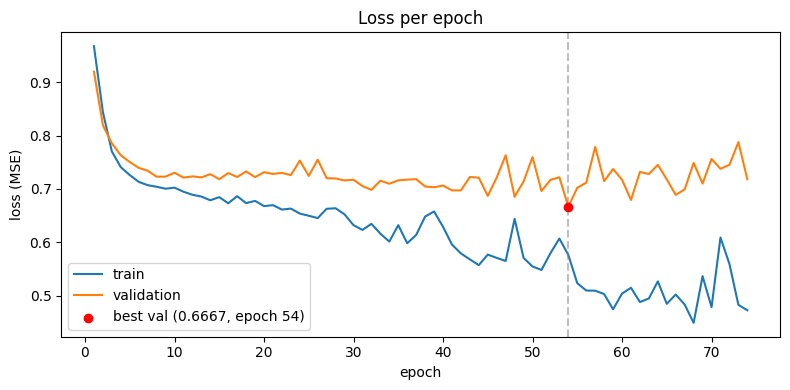

In [13]:
fig = plot_losses(train_losses, val_losses)
fig.savefig("losses.png", dpi=150)
plt.show()

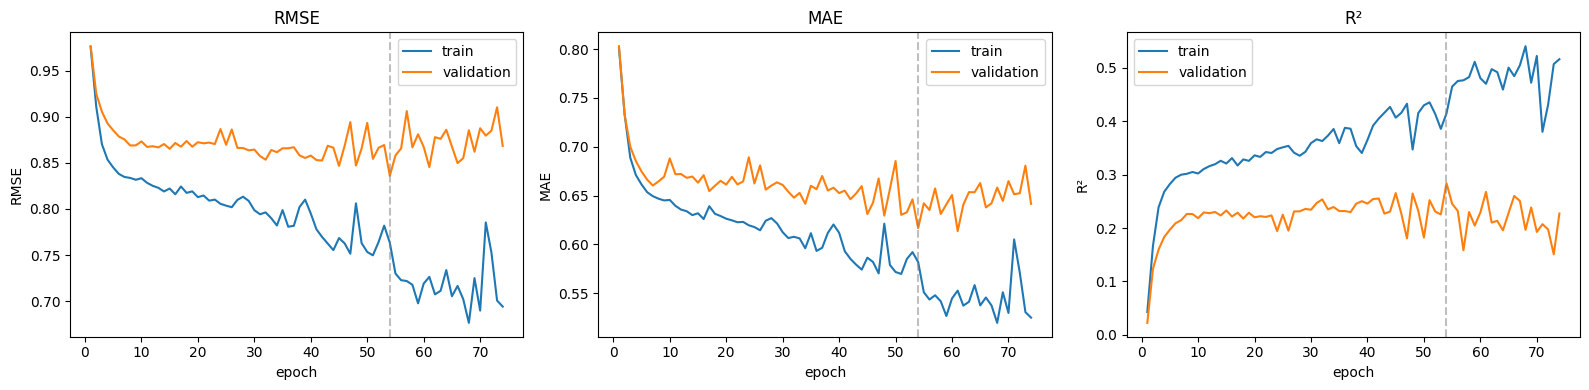

In [14]:
fig = plot_metrics(
    train_rmse_scores, val_rmse_scores,
    train_mae_scores, val_mae_scores,
    train_r2_scores, val_r2_scores,
)
fig.savefig("metrics.png", dpi=150)
plt.show()